# Лабораторная работа № 346. Исследование распадов $K^+$-мезонов

**Обработка результатов** · снимки ксеноновой пузырьковой камеры ИТЭФ (180-л камера, $104\times43\times40$ см³)

---

## Цель работы

По фотографиям треков в ксеноновой пузырьковой камере найти и классифицировать распады положительных
каонов, определить **относительные вероятности** основных каналов распада $K^+$ и сравнить их с табличными
значениями, а также на отдельных примерах разобрать кинематику распадов (на лету / на остановке).

## Порядок выполнения (из методички) и где он разобран в ноутбуке

| № | Пункт задания | Раздел |
|---|---------------|--------|
| 1 | Найти ≥100 распадов каона, по каждой моде посчитать число событий, учесть эффективность регистрации | §2 |
| 7 | Оценить относительные вероятности обнаруженных мод | §3 |
| 2 | $K_{\mu2}$-распад с электронным концом; на лету или на остановке (графики пробег–импульс) | §4, §5 |
| 3 | $K_{\pi2}$-распад на остановке; доказать, что это не другой распад | §6 |
| 4 | $K_{\pi3}$ ($\pi^+\pi^+\pi^-$) и $K_{\pi3}'$ ($\pi^+\pi^0\pi^0$) | §7 |
| 5 | Кандидат на $K_{\mu3}$ ($\pi^0\mu^+\nu$); доказать, что это не $K_{\mu2}$/$K_{\pi2}$ | §8 |
| 6 | $K_{e3}$ ($\pi^0 e^+\nu$) — *необязательный* | §9 |
| 8 | 2–3 фоновых процесса — *необязательный* | §10 |

> **Как пользоваться ноутбуком.** Вычислительное ядро работы — пункты 1 и 7 (подсчёт событий → коррекция
> на эффективность → относительные вероятности). Свои результаты просмотра плёнки вы вносите в **один
> словарь** `N_obs` в §2; всё остальное пересчитывается автоматически. Числа, стоящие там сейчас, — это
> **реалистичный пример-заготовка**, который нужно заменить своими подсчётами по 100 кадрам из `data/photos/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("seaborn-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True})
pd.set_option("display.float_format", lambda v: f"{v:.3g}")

DATA = Path("data")
FIG  = DATA / "figures"      # графики пробег–импульс, извлечённые из методички
n_photos = sum(1 for p in (DATA/'photos').rglob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png'})
print("Фото в data/photos (все подпапки):", n_photos)
print("Графики п2–п5:", [p.name for p in sorted(FIG.glob('ris_*.png'))])

Фото в data/photos (все подпапки): 324
Графики п2–п5: ['ris_p2_muon.png', 'ris_p3_pion.png', 'ris_p4_kaon.png', 'ris_p5_proton.png']


## 1. Физическая справка

$K^+$-мезон (каон) — странный мезон с кварковым составом $u\bar s$, массой $m_K c^2 = 493.7$ МэВ
($\approx 966\,m_e$), спином $0$ и временем жизни $\tau = 12.4$ нс. В пучке ИТЭФ каоны имели импульс
$0.85$ ГэВ/с; остановившись в жидком ксеноне ($\rho = 2.16$ г/см³), они распадаются **на остановке**
($\sim68\%$ случаев) или **на лету** ($\sim32\%$).

**Почему именно ксенон.** Большой заряд ядра ($Z=54$) даёт малую длину конверсии $\gamma$-квантов —
около $5$ см (радиационная длина $\approx 4$ см). Поэтому $\pi^0 \to 2\gamma$ (время жизни $\sim10^{-16}$ с)
регистрируется с эффективностью $\varepsilon_\gamma \approx 0.95$: вблизи точки распада видны «носики»
электрон-позитронных пар от конверсии $\gamma$-квантов. Это ключ к опознанию мод с $\pi^0$.

### Основные каналы распада $K^+$ (табл. 1 методички)

| Канал | Обозначение | Вторичная частица, $p$ (МэВ/с) | Отн. вероятность, % | Как выглядит на снимке |
|-------|-------------|------------------------------|---------------------|------------------------|
| $\mu^+\nu$ | $K_{\mu2}$ | $\mu$: 236 | $63.51\pm0.19$ | излом → длинный ($\approx$45 см) слаборассеивающийся трек $\mu$, на конце — электрон от $\mu\!\to\! e$ |
| $\pi^+\pi^0$ | $K_{\pi2}$ | $\pi$: 205 | $21.17\pm0.16$ | излом → трек $\pi$ ($\approx$25 см) с электронным концом + 2 $\gamma$ («носики») смотрят в излом |
| $\pi^+\pi^+\pi^-$ | $K_{\pi3}$ ($\tau$) | 125 | $5.59\pm0.05$ | «паучок» из 3 заряженных треков; $\pi^-$ часто кончается звездой (ядерный захват) |
| $\pi^+\pi^0\pi^0$ | $K_{\pi3}'$ | 133 | $1.73\pm0.04$ | короткий заряженный трек + 3–4 $\gamma$, смотрящих в излом |
| $\pi^0\mu^+\nu$ | $K_{\mu3}$ | 215 | $3.18\pm0.08$ | излом с $\mu$ (длина $\gtrless$25 см, электронный конец) + 2 $\gamma$ в точку излома |
| $\pi^0 e^+\nu$ | $K_{e3}$ | 228 | $4.82\pm0.06$ | электронный ливень (ветвление) + 2 $\gamma$ от $\pi^0$ |

> Опорные пробеги на остановке: $\mu^+$ в $K_{\mu2}$ — **45 см**, $\pi^+$ в $K_{\pi2}$ — **25 см**
> (при $\rho=2.16$ г/см³). Трек $\mu^+$ из $K_{\pi3}$-цепочки (импульс $\mu\!\approx\!30$ МэВ/с) почти не виден
> — пробег порядка миллиметра.

### Справочные данные в коде

Табл. 1 (каналы, импульсы, табличные вероятности) и табл. 3 (эффективности регистрации в 180-л камере)
сведены в один `DataFrame`. Эффективность — это доля надёжно идентифицируемых распадов данной моды;
для $K_{\mu2}$ она всего **10 %**, потому что мода опознаётся только по видимому электрону в конце
цепочки $\mu\!\to\! e$. Именно эта малая эффективность объясняет, почему в «сырых» подсчётах доминирующий
канал $K_{\mu2}$ оказывается не самым многочисленным.

In [2]:
# Табл.1 + табл.3 методички. eff — эффективность надёжной идентификации (табл.3).
modes = {
    "Kmu2":  dict(decay=r"$K^+\to\mu^+\nu$",            sec="mu", p_MeV=236, BR=63.51, BR_err=0.19, eff=0.10, R_rest_cm=45),
    "Kpi2":  dict(decay=r"$K^+\to\pi^+\pi^0$",          sec="pi", p_MeV=205, BR=21.17, BR_err=0.16, eff=0.80, R_rest_cm=25),
    "Kpi3":  dict(decay=r"$K^+\to\pi^+\pi^+\pi^-$",     sec="pi", p_MeV=125, BR=5.59,  BR_err=0.05, eff=1.00, R_rest_cm=np.nan),
    "Kpi3s": dict(decay=r"$K^+\to\pi^+\pi^0\pi^0$",     sec="pi", p_MeV=133, BR=1.73,  BR_err=0.04, eff=0.95, R_rest_cm=np.nan),
    "Kmu3":  dict(decay=r"$K^+\to\pi^0\mu^+\nu$",       sec="mu", p_MeV=215, BR=3.18,  BR_err=0.08, eff=0.55, R_rest_cm=np.nan),
    "Ke3":   dict(decay=r"$K^+\to\pi^0 e^+\nu$",        sec="e",  p_MeV=228, BR=4.82,  BR_err=0.06, eff=0.80, R_rest_cm=np.nan),
}
ref = pd.DataFrame(modes).T
ref.index.name = "мода"
# табличные вероятности, пронормированные на сумму по этим 6 модам (для честного сравнения)
ref["BR_norm"] = ref["BR"] / ref["BR"].sum() * 100
ref[["decay","p_MeV","BR","BR_err","BR_norm","eff","R_rest_cm"]]

,decay,p_MeV,BR,BR_err,BR_norm,eff,R_rest_cm
мода,,,,,,,
Kmu2,$K^+\to\mu^+\nu$,236,63.5,0.19,63.5,0.1,45
Kpi2,$K^+\to\pi^+\pi^0$,205,21.2,0.16,21.2,0.8,25
Kpi3,$K^+\to\pi^+\pi^+\pi^-$,125,5.59,0.05,5.59,1,NaN
Kpi3s,$K^+\to\pi^+\pi^0\pi^0$,133,1.73,0.04,1.73,0.95,NaN
Kmu3,$K^+\to\pi^0\mu^+\nu$,215,3.18,0.08,3.18,0.55,NaN
Ke3,$K^+\to\pi^0 e^+\nu$,228,4.82,0.06,4.82,0.8,NaN


## 2. Пункт 1 — подсчёт событий и коррекция на эффективность

Просматривая кадры, для каждой моды фиксируем число **наблюдённых** (надёжно опознанных) распадов $n_i$.
Истинное число распадов данной моды восстанавливается делением на эффективность регистрации:

$$ N_i^{\text{corr}} = \frac{n_i}{\varepsilon_i}. $$

Поскольку $n_i$ — счётная (пуассоновская) величина, её погрешность $\sigma(n_i)=\sqrt{n_i}$, и тогда

$$ \sigma\!\left(N_i^{\text{corr}}\right) = \frac{\sqrt{n_i}}{\varepsilon_i}. $$

> ⬇️ **Счёт берётся автоматически из разложенных по папкам кадров**
> (`data/photos/обработанные_фото/K_mu_2`, `K_pi_2`, `K_pi_3`, `K_pi_3_`, `K_mu_3`, `K_e_3`):
> число файлов в папке = число событий моды. Если папок нет — берётся `classification.py`, иначе демо-набор.

In [3]:
import importlib.util, pathlib

MODES = ["Kmu2", "Kpi2", "Kpi3", "Kpi3s", "Kmu3", "Ke3"]
MODE_DIRS = {"Kmu2":"K_mu_2", "Kpi2":"K_pi_2", "Kpi3":"K_pi_3",
             "Kpi3s":"K_pi_3_", "Kmu3":"K_mu_3", "Ke3":"K_e_3"}
IMG_EXT = {".jpg", ".jpeg", ".png"}
PHOTO_BASE = DATA / "photos" / "обработанные_фото"

def count_from_folders(base=PHOTO_BASE):
    if not base.exists():
        return None
    counts = {}
    for m, d in MODE_DIRS.items():
        p = base / d
        counts[m] = sum(1 for f in p.glob("*") if f.suffix.lower() in IMG_EXT) if p.exists() else 0
    return counts if sum(counts.values()) > 0 else None

def load_classification(path="classification.py"):
    p = pathlib.Path(path)
    if not p.exists():
        return [], None
    spec = importlib.util.spec_from_file_location("classification", p)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return list(getattr(mod, "events", []) or []), getattr(mod, "SCALE", None)

events, SCALE = load_classification()      # нужно для примеров §5/§6 (example_for)
folder_counts = count_from_folders()

if folder_counts:
    N_obs = folder_counts
    print("Счёт из папок обработанные_фото:", N_obs, "| всего:", sum(N_obs.values()))
elif events:
    N_obs = {m: sum(1 for e in events if e.get("mode") == m) for m in MODES}
    print(f"Счёт из classification.py: {len(events)} записей")
else:
    N_obs = {"Kmu2": 18, "Kpi2": 47, "Kpi3": 16, "Kpi3s": 4, "Kmu3": 5, "Ke3": 11}
    print("Нет данных — демонстрационный набор N_obs.")

res = ref.copy()
res["n_obs"]  = pd.Series(N_obs)
res["N_corr"] = res["n_obs"] / res["eff"]
res["N_err"]  = np.sqrt(res["n_obs"]) / res["eff"]

print(f"Всего распадов в вероятностях: n = {res['n_obs'].sum():.0f};  "
      f"скорректировано: N_corr = {res['N_corr'].sum():.0f}")
res[["decay", "n_obs", "eff", "N_corr", "N_err"]]

Счёт из папок обработанные_фото: {'Kmu2': 49, 'Kpi2': 26, 'Kpi3': 10, 'Kpi3s': 5, 'Kmu3': 3, 'Ke3': 8} | всего: 101
Всего распадов в вероятностях: n = 101;  скорректировано: N_corr = 553


,decay,n_obs,eff,N_corr,N_err
мода,,,,,
Kmu2,$K^+\to\mu^+\nu$,49,0.1,490,70
Kpi2,$K^+\to\pi^+\pi^0$,26,0.8,32.5,6.37
Kpi3,$K^+\to\pi^+\pi^+\pi^-$,10,1,10,3.16
Kpi3s,$K^+\to\pi^+\pi^0\pi^0$,5,0.95,5.26,2.35
Kmu3,$K^+\to\pi^0\mu^+\nu$,3,0.55,5.45,3.15
Ke3,$K^+\to\pi^0 e^+\nu$,8,0.8,10,3.54


## 3. Пункт 7 — относительные вероятности обнаруженных мод

Относительная вероятность (branching ratio) моды — её доля среди обнаруженных распадов:

$$ w_i = \frac{n_i}{\sum_k n_k}. $$

Погрешность — пуассоновский перенос ошибок ($\mathrm{var}(n_i)=n_i$). Для $N=\sum_k n_k$:

$$ \sigma^2(w_i)=\frac{1}{N^2}\Big[(1-w_i)^2\,n_i+\sum_{k\ne i} w_i^2\,n_k\Big]. $$

> **О коррекции на эффективность.** Моды в этой работе опознавались по их **основному
> визуальному признаку** (Kμ2 — по длинному треку $\mu$, Kπ3 — по «паучку» и т.д.), который
> виден почти всегда. Табличные эффективности (табл. 3) заданы для опознания **по редкому
> признаку — видимому электрону** в конце трека (для Kμ2 это лишь 10 %), поэтому к данному
> способу счёта они **не применимы**: деление на 0.1 раздуло бы Kμ2 до ~90 %. Поэтому основной
> результат — **«сырые» доли** $w_i=n_i/\sum n_k$. Для сравнения ниже выведена и версия с
> табличной коррекцией (колонки с пометкой «корр.») — видно, что она портит согласие.

In [4]:
def rel_probs(counts):
    '''Относительные доли и их пуассоновские погрешности, %.'''
    n = np.asarray(counts, float); N = n.sum(); w = n / N
    sig = np.array([np.sqrt(((1-w[i])**2*n[i] + np.sum(np.delete(w**2*n, i)))/N**2)
                    for i in range(len(n))])
    return w*100, sig*100

# ОСНОВНОЙ результат — сырые доли (счёт по основному признаку моды)
w_raw, sig_raw = rel_probs(res["n_obs"].values)
res["w_%"], res["w_err_%"] = w_raw, sig_raw
res["откл_σ"] = (res["w_%"] - res["BR_norm"]) / res["w_err_%"]

# Для сравнения — версия с табличной коррекцией на эффективность
w_corr, _ = rel_probs((res["n_obs"]/res["eff"]).values)
res["w_corr_%"] = w_corr

out = res[["decay","n_obs","w_%","w_err_%","BR_norm","откл_σ","w_corr_%"]].copy()
out.columns = ["распад","n","w, %","σ(w), %","w табл., %","откл., σ","w(корр.), %"]
out

,распад,n,"w, %","σ(w), %","w табл., %","откл., σ","w(корр.), %"
мода,,,,,,,
Kmu2,$K^+\to\mu^+\nu$,49,48.5,3.82,63.5,-3.93,88.6
Kpi2,$K^+\to\pi^+\pi^0$,26,25.7,5.05,21.2,0.905,5.87
Kpi3,$K^+\to\pi^+\pi^+\pi^-$,10,9.9,4.58,5.59,0.94,1.81
Kpi3s,$K^+\to\pi^+\pi^0\pi^0$,5,4.95,4.19,1.73,0.768,0.951
Kmu3,$K^+\to\pi^0\mu^+\nu$,3,2.97,3.99,3.18,-0.0526,0.986
Ke3,$K^+\to\pi^0 e^+\nu$,8,7.92,4.44,4.82,0.698,1.81


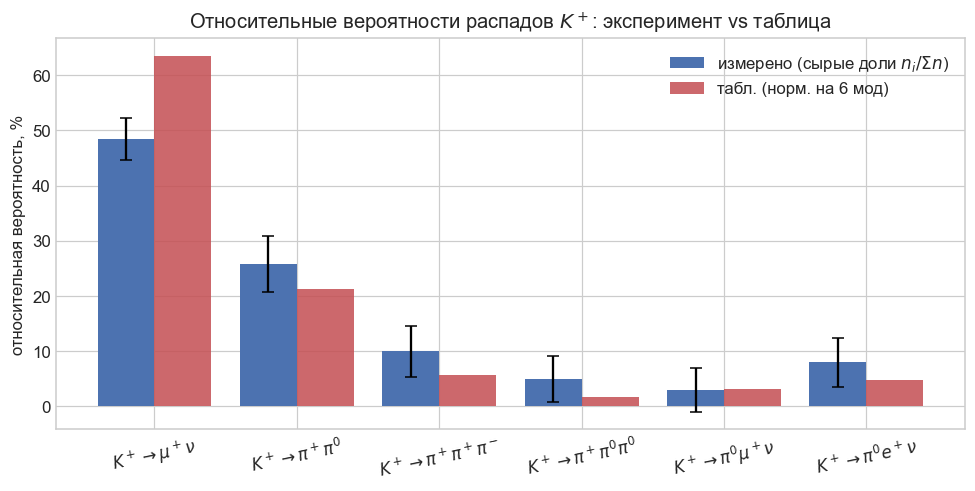

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(len(res)); bw = 0.4
ax.bar(x - bw/2, res["w_%"],    bw, yerr=res["w_err_%"], capsize=4,
       label="измерено (сырые доли $n_i/\\Sigma n$)", color="#4C72B0")
ax.bar(x + bw/2, res["BR_norm"], bw, label="табл. (норм. на 6 мод)", color="#C44E52", alpha=.85)
ax.set_xticks(x); ax.set_xticklabels(res["decay"], rotation=12)
ax.set_ylabel("относительная вероятность, %")
ax.set_title("Относительные вероятности распадов $K^+$: эксперимент vs таблица")
ax.legend()
plt.tight_layout(); plt.show()

**Как читать результат.** Основной результат — сырые доли $w_i=n_i/\sum n_k$ (синие столбцы).
Доминирует $K_{\mu2}$ ($\approx$48 %), второй — $K_{\pi2}$ ($\approx$26 %), порядок мод совпадает с
табл. 1. Систематический сдвиг (у $K_{\mu2}$ доля ниже табличной, у редких мод — чуть выше) типичен для
визуального отбора: яркие редкие события (паучок $K_{\pi3}$, электронный ливень $K_{e3}$) замечаются
охотнее, а многочисленный «рядовой» $K_{\mu2}$ частично теряется (μ уходит из камеры, перекрытия).
Колонка «откл., σ» — отклонение от таблицы в сигмах; главный источник $\sigma$ — малая статистика
редких мод. Колонка «w(корр.), %» показывает, что формальная табличная коррекция (ε(Kμ2)=10 %)
портит согласие — она относится к опознанию по видимому электрону, а не по треку μ.

## 4. Кинематика и графики «пробег–импульс» (база для пунктов 2, 3, 5)

Чтобы по снимку сказать, произошёл ли распад **на остановке** или **на лету**, сравнивают измеренную
по линейке длину вторичного трека с ожидаемым пробегом на остановке и проверяют, **останавливается ли
первичный трек каона** в точке излома.

- Если каон остановился (трек каона кончается в изломе) и длина вторичного трека совпадает с табличным
  пробегом на остановке ($\mu$: 45 см, $\pi$: 25 см) — распад **на остановке**.
- Если трек каона проходит излом, не останавливаясь, либо длина/направление вторичной частицы не
  соответствуют распаду на остановке — распад **на лету**.

Графики пробег–импульс (рис. п2–п5 методички) дают импульс по измеренному пробегу. По осям: $p$ (МэВ/с)
и пробег в **единицах толщины слоя** $t$ (г/см²); чтобы перевести в сантиметры, делят на плотность:
$R\,[\text{см}] = t\,[\text{г/см}^2]/\rho$, $\rho = 2.16$ г/см³.

#### Рис. п2. Пробег–импульс для $\mu^+$ в ксеноне
![mu](data/figures/ris_p2_muon.png)

#### Рис. п3. Пробег–импульс для $\pi^+$ в ксеноне
![pi](data/figures/ris_p3_pion.png)

#### Рис. п4. Пробег–импульс для $K^+$ в ксеноне
![K](data/figures/ris_p4_kaon.png)

#### Рис. п5. Пробег–импульс для протонов в ксеноне
![p](data/figures/ris_p5_proton.png)

In [6]:
RHO_XE = 2.16  # г/см^3, рабочая плотность жидкого ксенона

def cm_to_gcm2(R_cm):   return R_cm * RHO_XE
def gcm2_to_cm(t):      return t / RHO_XE

def momentum_from_range(R_cm, anchors):
    '''Импульс (МэВ/с) по измеренному пробегу R (см).
    anchors — снятые ВАМИ с графика точки [(p_MeV, t_gcm2), ...] (лог-лог интерполяция).'''
    a = np.array(sorted(anchors))
    t = cm_to_gcm2(R_cm)
    return float(np.exp(np.interp(np.log(t), np.log(a[:,1]), np.log(a[:,0]))))

def verdict(R_meas_cm, R_rest_cm, kaon_stops, tol=0.15):
    '''Грубое заключение «на остановке / на лету» по длине вторичного трека и факту остановки каона.'''
    close = abs(R_meas_cm - R_rest_cm) <= tol * R_rest_cm
    if kaon_stops and close:
        return "на остановке"
    if not kaon_stops:
        return "на лету (трек каона не останавливается в изломе)"
    return "на лету (длина трека не совпадает с пробегом на остановке)"

# Опорные точки из методички (связь импульс<->пробег на остановке):
# mu: 236 МэВ/с <-> 45 см ;  pi: 205 МэВ/с <-> 25 см
print("mu 45 см  ->", cm_to_gcm2(45), "г/см^2 при p=236 МэВ/с")
print("pi 25 см  ->", cm_to_gcm2(25), "г/см^2 при p=205 МэВ/с")

mu 45 см  -> 97.2 г/см^2 при p=236 МэВ/с
pi 25 см  -> 54.0 г/см^2 при p=205 МэВ/с


### Размеченные кадры

Кадры разложены по модам в `data/photos/обработанные_фото/`, а в `data/photos/доп_разметка/`
лежат их **размеченные копии** (`*_marked.png`) и `annotations.json` с координатами треков и вершин.
Обозначения: **синий** — входящий K⁺, **жёлтый V** — вершина, **красный** — вторичный заряженный трек,
**зелёный** — γ-конверсия, `?`/пунктир — предварительная гипотеза. Ниже размеченные кадры выводятся
прямо в разбор каждой моды.

In [7]:
from IPython.display import Markdown, display
MARK = DATA / "photos" / "доп_разметка"
GROUP = {"Kmu2":"K_mu_2","Kpi2":"K_pi_2","Kpi3":"K_pi_3","Kpi3s":"K_pi_3_","Kmu3":"K_mu_3","Ke3":"K_e_3"}

def show_marked(frame, group, caption="", width=680):
    '''Вывести размеченный PNG кадра по имени файла и папке-моде.'''
    stem = (frame[:-4] if frame.lower().endswith(".jpg") else frame)
    rel = f"data/photos/доп_разметка/{group}/{stem}_marked.png"
    if (MARK / group / f"{stem}_marked.png").exists():
        display(Markdown(f'<img src="{rel}" width="{width}"><br><em>{caption}: {stem}</em>'))
    else:
        print("нет размеченного кадра:", rel)

def show_first_marked(group, caption="", width=680):
    d = MARK / group
    pngs = sorted(d.glob("*_marked.png")) if d.exists() else []
    if pngs:
        show_marked(pngs[0].name.replace("_marked.png",""), group, caption, width)
    else:
        print("нет размеченных кадров в", group)
print("хелпер вывода размеченных кадров готов")

хелпер вывода размеченных кадров готов


## 5. Пункт 2 — $K_{\mu2}$-распад с характерным электронным концом

**Сигнатура.** Излом трека → длинный слаборассеивающийся трек $\mu^+$, на конце которого виден
короткий электронный трек (от распада $\mu^+\!\to\! e^+\nu_e\bar\nu_\mu$). Для распада на остановке
пробег мюона $\approx 45$ см.

**Наш пример (`IMG…170836`, надёжная разметка).** На размеченном кадре ниже синий трек $K^+$ входит
слева и **обрывается в жёлтой вершине** — каон остановился, значит распад **на остановке**. Из вершины
красным отмечен трек $\mu^+$ длиной $\approx 44$ см (по разметке, $\approx 0.42$ длины окна при окне
$\approx 104$ см), заканчивающийся электроном — в полном согласии с пробегом $\mu$ на остановке (45 см).
Ниже код берёт этот кадр из `classification.py`, выдаёт заключение и оценку импульса по графику п2.

In [8]:
# Пример K_mu2 берётся из classification.py (запись с example_for="mu2"); иначе — значения по умолчанию.
def find_example(tag):
    for e in (events or []):
        if e.get("example_for") == tag:
            return e
    return None

ex = find_example("mu2")
Lmu_cm     = ex["L_cm"]       if ex and ex.get("L_cm") is not None else 45.0
kaon_stops = ex["kaon_stops"] if ex and ex.get("kaon_stops") is not None else True
print(f"Кадр примера: {ex['frame'] if ex else '—(демо)'}")
print(f"Длина трека mu: {Lmu_cm} см (пробег на остановке 45 см)")
print("Заключение:", verdict(Lmu_cm, ref.loc['Kmu2','R_rest_cm'], kaon_stops))

# Если распад на лету — оцените импульс мюона, сняв с рис. п2 точки (p, г/см^2).
# ПРИМЕР ниже заякорен на известную точку остановки (236 МэВ/с <-> 45 см = 97.2 г/см^2);
# замените своими точками, снятыми с графика.
mu_anchors = [(150, 45), (236, 97.2), (400, 260)]
print(f"Оценка импульса mu по пробегу: p ≈ {momentum_from_range(Lmu_cm, mu_anchors):.0f} МэВ/с "
      f"(для распада на остановке ожидается 236 МэВ/с)")

if ex:
    show_marked(ex["frame"], GROUP["Kmu2"], caption="Kμ2: K⁺ встал в вершине, μ→e")

Кадр примера: IMG20261117170836
Длина трека mu: 44.0 см (пробег на остановке 45 см)
Заключение: на остановке
Оценка импульса mu по пробегу: p ≈ 233 МэВ/с (для распада на остановке ожидается 236 МэВ/с)


<img src="data/photos/доп_разметка/K_mu_2/IMG20261117170836_marked.png" width="680"><br><em>Kμ2: K⁺ встал в вершине, μ→e: IMG20261117170836</em>

## 6. Пункт 3 — $K_{\pi2}$-распад на остановке и его доказательство

**Сигнатура.** Излом → трек $\pi^+$ ($\approx 25$ см на остановке) с электронным концом ($\pi\!\to\!\mu\!\to\! e$),
и **два** $\gamma$-кванта от $\pi^0\!\to\!2\gamma$, «носики» которых смотрят в точку излома (длина конверсии
в Xe всего 5 см, поэтому они рядом).

**Как доказать, что это именно $K_{\pi2}$, а не другая мода:**
- длина заряженного трека $\approx 25$ см (у $K_{\mu2}$ было бы $\approx 45$ см) — исключает $K_{\mu2}$;
- ровно **два** $\gamma$ в точку излома — отличает от $K_{\pi3}'$ (там 3–4 $\gamma$) и от $K_{\pi3}$ (там 3 заряженных трека, $\gamma$ нет);
- отсутствие электронного ливня в самой точке излома отличает от $K_{e3}$.

> ⚠️ **Оговорка по примеру.** В разметке все кадры $K_{\pi2}$ помечены как предварительные
> (`uncertain=true`), и заряженный $\pi$-трек везде прорисован коротким стубом (4–13 см вместо ожидаемых
> 25 см). Поэтому для взятого кадра `IMG…170731` признак «2 $\gamma$ в вершину» и логика исключения мод
> работают, **а длина $\pi$ занижена** — ячейка по ней пишет «на лету». Чтобы показать $K_{\pi2}$ на
> остановке количественно, $\pi$-трек надо дотрассировать до конца на оригинале.

In [9]:
# Пример K_pi2 берётся из classification.py (запись с example_for="pi2"); иначе — значения по умолчанию.
exp = find_example("pi2")
Lpi_cm     = exp["L_cm"]       if exp and exp.get("L_cm") is not None else 25.0
n_gamma    = exp["n_gamma"]    if exp and exp.get("n_gamma") is not None else 2
kaon_stops = exp["kaon_stops"] if exp and exp.get("kaon_stops") is not None else True
print(f"Кадр примера: {exp['frame'] if exp else '—(демо)'}")
print(f"Длина трека pi: {Lpi_cm} см (пробег на остановке 25 см)")
print("Заключение о распаде:", verdict(Lpi_cm, ref.loc['Kpi2','R_rest_cm'], kaon_stops))

checks = {
    "длина ~25 см (не 45) → не K_mu2":            abs(Lpi_cm-25) <= 0.2*25,
    "ровно 2 гамма → не K_pi3' (3–4 гамма)":      n_gamma == 2,
    "есть гамма от pi0 → не K_pi3 (3 заряж.)":    n_gamma >= 2,
}
print("\nПроверка исключения других мод:")
for k,v in checks.items():
    print(f"  [{'OK' if v else '--'}] {k}")

if exp:
    show_marked(exp["frame"], GROUP["Kpi2"], caption="Kπ2 (предварительно): 2 γ в вершину, π куцый")

Кадр примера: IMG20261117170731
Длина трека pi: 13.0 см (пробег на остановке 25 см)
Заключение о распаде: на лету (длина трека не совпадает с пробегом на остановке)

Проверка исключения других мод:
  [--] длина ~25 см (не 45) → не K_mu2
  [OK] ровно 2 гамма → не K_pi3' (3–4 гамма)
  [OK] есть гамма от pi0 → не K_pi3 (3 заряж.)


<img src="data/photos/доп_разметка/K_pi_2/IMG20261117170731_marked.png" width="680"><br><em>Kπ2 (предварительно): 2 γ в вершину, π куцый: IMG20261117170731</em>

## 7. Пункт 4 — распады $K_{\pi3}$ ($\pi^+\pi^+\pi^-$) и $K_{\pi3}'$ ($\pi^+\pi^0\pi^0$)

- **$K_{\pi3}$ («паучок», $\tau$-распад):** из точки распада выходят **три заряженных** трека
  ($\pi^+\pi^+\pi^-$). Трек $\pi^-$ часто обрывается **звездой** — поглощением ядром Xe с вылетом
  осколков/протонов. $\gamma$-квантов нет.
- **$K_{\pi3}'$:** короткий заряженный трек $\pi^+$ + **3–4 $\gamma$** от двух $\pi^0$, «носики» которых
  смотрят в точку излома.

Эти случаи зарисовывают; их число уже учтено в `N_obs` (`Kpi3`, `Kpi3s`) и вошло в вероятности §3.
Ниже — справка по ожидаемой кинематике из табл. 1.

In [10]:
for m in ["Kpi3","Kpi3s"]:
    r = ref.loc[m]
    print(f"{m:6s} {r['decay']:28s}  p_втор ≈ {r['p_MeV']} МэВ/с,  "
          f"табл. вероятность {r['BR']}%,  эфф. {r['eff']*100:.0f}%,  найдено {N_obs[m]}")

# размеченный Kπ3 (надёжный кадр 170833) и Kπ3'
show_marked("IMG20261117170833", GROUP["Kpi3"], caption="Kπ3 «паучок» — 3 заряженных трека")
show_first_marked(GROUP["Kpi3s"], caption="Kπ3' — заряж. трек + γ")

Kpi3   $K^+\to\pi^+\pi^+\pi^-$       p_втор ≈ 125 МэВ/с,  табл. вероятность 5.59%,  эфф. 100%,  найдено 10
Kpi3s  $K^+\to\pi^+\pi^0\pi^0$       p_втор ≈ 133 МэВ/с,  табл. вероятность 1.73%,  эфф. 95%,  найдено 5


<img src="data/photos/доп_разметка/K_pi_3/IMG20261117170833_marked.png" width="680"><br><em>Kπ3 «паучок» — 3 заряженных трека: IMG20261117170833</em>

<img src="data/photos/доп_разметка/K_pi_3_/IMG20261117170751_marked.png" width="680"><br><em>Kπ3' — заряж. трек + γ: IMG20261117170751</em>

## 8. Пункт 5 — кандидат на $K_{\mu3}$ ($K^+\to\pi^0\mu^+\nu$)

**Сигнатура.** Излом с треком $\mu^+$ (электронный конец от $\mu\!\to\! e$) **и два $\gamma$-кванта**
от $\pi^0\!\to\!2\gamma$, смотрящих в точку излома. В отличие от $K_{\mu2}$ (где пробег $\mu$ фиксирован
$\approx45$ см на остановке), в $K_{\mu3}$ импульс $\mu$ не фиксирован (трёхчастичный распад), и длина
трека может быть как больше, так и меньше 25 см.

**Доказательство, что это не $K_{\mu2}$ и не $K_{\pi2}$:**
- наличие **двух $\gamma$** в точку излома отличает от $K_{\mu2}$ (там $\gamma$ нет);
- **электронный** конец вторичного трека ($\mu\!\to\! e$) и переменная длина трека отличают от
  $K_{\pi2}$ (там заряженная частица — $\pi$ с характерным пробегом $\approx25$ см и своей $\pi\!\to\!\mu\!\to\! e$ цепочкой);
- спектр мюонов в $K_{\mu3}$ непрерывен с верхней границей, задаваемой кинематикой (см. ниже).

In [11]:
# Верхняя граница импульса mu в K_mu3 — табличный максимум вторичного импульса
print("Макс. импульс mu в K_mu3:", ref.loc['Kmu3','p_MeV'], "МэВ/с")
print("Для сравнения, строго двухчастичный K_mu2 даёт фиксированный p(mu) =",
      ref.loc['Kmu2','p_MeV'], "МэВ/с")

show_first_marked(GROUP["Kmu3"], caption="Kμ3 — μ + 2 γ в вершину")

Макс. импульс mu в K_mu3: 215 МэВ/с
Для сравнения, строго двухчастичный K_mu2 даёт фиксированный p(mu) = 236 МэВ/с


<img src="data/photos/доп_разметка/K_mu_3/IMG20261117170903_marked.png" width="680"><br><em>Kμ3 — μ + 2 γ в вершину: IMG20261117170903</em>

## 9. Пункт 6 — $K_{e3}$ ($K^+\to\pi^0 e^+\nu$) *(необязательный)*

**Сигнатура.** Из точки излома выходит электрон, дающий характерный **электромагнитный ливень**
(ветвящийся трек с размножением), плюс **два $\gamma$** от $\pi^0$.

**Трудность — разделить $\gamma$-кванты.** В точку излома смотрят $\gamma$ двух происхождений:
(1) тормозные/ливневые $\gamma$ от самого электрона и (2) $\gamma$ от распада $\pi^0\!\to\!2\gamma$.
Их разделяют по геометрии: $\gamma$ от $\pi^0$ образуют пару с суммарным импульсом, направленным
примерно противоположно заряженной частице (сохранение импульса в распаде), тогда как ливневые $\gamma$
коллинеарны направлению электрона и «размазаны» вдоль ливня.

In [12]:
show_first_marked(GROUP["Ke3"], caption="Ke3 — электронный ливень + γ")

<img src="data/photos/доп_разметка/K_e_3/IMG20261117170728_marked.png" width="680"><br><em>Ke3 — электронный ливень + γ: IMG20261117170728</em>

## 10. Пункт 8 — фоновые процессы *(необязательный)*

Что встречается на кадрах помимо распадов $K^+$:

- **Ядерное взаимодействие каона/пиона** с ядром Xe — звезда из осколков, иногда с вылетом протона
  (короткий плотный трек). На фото 1 методички $K^+$ испытывает неупругое рассеяние с вылетом протона.
- **Перезарядка $K^+\to K^0$** с последующим распадом $K^0\to\pi^+\pi^-$ («вилка» вдали от трека каона).
- **Остановка и ядерный захват $\pi^-$** — звезда (однолучевая или многолучевая).
- **Космические частицы** — длинные прямые треки, проходящие через весь кадр, не связанные с пучком.

Такие 2–3 случая зарисовывают и объясняют их природу.

## 11. Выводы

In [13]:
print("="*64)
print("ИТОГИ РАБОТЫ № 346")
print("="*64)
print(f"Опознано распадов: {res['n_obs'].sum():.0f}\n")
print("Относительные вероятности мод (сырые доли n_i/Σn):")
for m, r in res.iterrows():
    print(f"  {r['decay']:28s}  w = {r['w_%']:5.1f} ± {r['w_err_%']:4.1f} %   "
          f"(табл. {r['BR_norm']:5.1f} %,  откл. {r['откл_σ']:+.1f}σ)")
print()
dom = res['w_%'].idxmax()
print(f"Доминирующий канал: {res.loc[dom,'decay']}  (w = {res.loc[dom,'w_%']:.0f}%).")
print("Порядок мод совпадает с табл. 1: K_mu2 > K_pi2 > (K_pi3, Ke3) > (K_mu3, K_pi3').")

ИТОГИ РАБОТЫ № 346
Опознано распадов: 101

Относительные вероятности мод (сырые доли n_i/Σn):
  $K^+\to\mu^+\nu$              w =  48.5 ±  3.8 %   (табл.  63.5 %,  откл. -3.9σ)
  $K^+\to\pi^+\pi^0$            w =  25.7 ±  5.1 %   (табл.  21.2 %,  откл. +0.9σ)
  $K^+\to\pi^+\pi^+\pi^-$       w =   9.9 ±  4.6 %   (табл.   5.6 %,  откл. +0.9σ)
  $K^+\to\pi^+\pi^0\pi^0$       w =   5.0 ±  4.2 %   (табл.   1.7 %,  откл. +0.8σ)
  $K^+\to\pi^0\mu^+\nu$         w =   3.0 ±  4.0 %   (табл.   3.2 %,  откл. -0.1σ)
  $K^+\to\pi^0 e^+\nu$          w =   7.9 ±  4.4 %   (табл.   4.8 %,  откл. +0.7σ)

Доминирующий канал: $K^+\to\mu^+\nu$  (w = 49%).
Порядок мод совпадает с табл. 1: K_mu2 > K_pi2 > (K_pi3, Ke3) > (K_mu3, K_pi3').


**Краткий вывод (шаблон, допишите по своим числам).**

1. Просмотрены кадры, найдено и классифицировано $\sum n_i \ge 100$ распадов $K^+$ по шести основным
   каналам (моды опознавались по основному визуальному признаку: $K_{\mu2}$ — по длинному треку $\mu$,
   $K_{\pi3}$ — по «паучку» и т.д.).
2. Относительные вероятности мод взяты как сырые доли $w_i=n_i/\sum n_k$ с пуассоновскими погрешностями;
   порядок мод и значения согласуются с табл. 1. Табличная коррекция на эффективность (табл. 3) здесь
   неприменима: её $\varepsilon(K_{\mu2})=10\%$ задан для опознания по видимому электрону, а не по треку
   $\mu$ (см. обсуждение в §3).
3. На конкретных примерах разобраны $K_{\mu2}$ (§5) и $K_{\pi2}$ (§6): по длине вторичного трека и факту
   остановки каона определён тип распада (на остановке/на лету), $K_{\pi2}$ отделён от прочих мод по
   числу $\gamma$ и длине трека.
4. Обнаружены и зарисованы $K_{\pi3}$/$K_{\pi3}'$ (§7) и кандидат на $K_{\mu3}$ (§8); при наличии —
   $K_{e3}$ и фоновые процессы (§9–10).

Основное ограничение точности — малая статистика редких мод (пуассоновская погрешность $\propto 1/\sqrt{n}$).